<h1>Project Group 30: Predicting Repeat Purchases with ML</h1>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Notebook 2 of 3</b>: III. Binary Classification & Optimization. It starts from the prepared training data of Notebook 1 (<b>data/interim</b>) and uses the same split: 4 time folds for every decision, the holdout once at the end. test.csv is not used in this notebook.</p>

</div>

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from scipy.stats import chi2_contingency, loguniform, randint, spearmanr, uniform
from scipy.stats.contingency import association

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, GroupKFold, RandomizedSearchCV, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, RobustScaler
from sklearn.tree import DecisionTreeClassifier

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import preprocessing as prep
from preprocessing import TARGET, RANDOM_STATE, PLOT_BLUE, PLOT_PURPLE

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 90)

In [2]:
# prepared training purchases of notebook 1 and the same split
train = prep.load_interim("../data/interim")
development, holdout, inner_folds = prep.split_development_holdout(train)

X_dev, y_dev = development.drop(columns=TARGET), development[TARGET]
X_holdout, y_holdout = holdout.drop(columns=TARGET), holdout[TARGET]
print(f"Development: {len(X_dev)} rows, repeat rate {y_dev.mean():.3f}")
print(f"Holdout: {len(X_holdout)} rows, repeat rate {y_holdout.mean():.3f}")
print("Inner folds (training rows, validation rows):",
      [(len(fit), len(val)) for fit, val in inner_folds])

Development: 5207 rows, repeat rate 0.549
Holdout: 1078 rows, repeat rate 0.604
Inner folds (training rows, validation rows): [(932, 1041), (1885, 1041), (2992, 1041), (3903, 1041)]


<a id="classification"></a>

<h1>III. Binary Classification & Optimization</h1>

<h2>Explanation of model assessment strategy and metrics used</h2>

<h3>Assessment strategy</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>One split for everything</b> (Notebook 1, Section I): 4 time folds with a 90-day gap for every decision, and the newest 1,078 purchases as a <b>holdout</b> that no decision in this notebook uses</li>
  <li>The folds differ in difficulty (the first trains on 932 rows, the last on 3,903) --> two candidates are compared <b>fold by fold</b>, not only by their mean</li>
</ul>

</div>

<h3>Metrics and baseline</h3>

In [3]:
# baseline: always predict a repeat
always_repeat = DummyClassifier(strategy="constant", constant=1)
baseline_folds = []
for fold, (fit_idx, val_idx) in enumerate(inner_folds, start=1):
    always_repeat.fit(X_dev.iloc[fit_idx], y_dev.iloc[fit_idx])
    fold_f1 = f1_score(y_dev.iloc[val_idx], always_repeat.predict(X_dev.iloc[val_idx]))
    baseline_folds.append(fold_f1)
    print(f"Inner fold {fold}: repeat rate {y_dev.iloc[val_idx].mean():.3f}, "
          f"F1 of always predicting a repeat {fold_f1:.3f}")
baseline_folds = np.array(baseline_folds)
baseline_holdout = f1_score(y_holdout, np.ones(len(y_holdout)))
print(f"Holdout: repeat rate {y_holdout.mean():.3f}, "
      f"F1 of always predicting a repeat {baseline_holdout:.3f}")
print(f"Mean baseline F1 on the inner folds: {baseline_folds.mean():.4f}")

Inner fold 1: repeat rate 0.591, F1 of always predicting a repeat 0.743
Inner fold 2: repeat rate 0.530, F1 of always predicting a repeat 0.693
Inner fold 3: repeat rate 0.581, F1 of always predicting a repeat 0.735
Inner fold 4: repeat rate 0.510, F1 of always predicting a repeat 0.676
Holdout: repeat rate 0.604, F1 of always predicting a repeat 0.753
Mean baseline F1 on the inner folds: 0.7116


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>F1 of the repeat class</b> decides everything: it is the Kaggle metric, and it balances precision (how many predicted repeat buyers return) and recall (how many repeat buyers are found). A model can not win by calling everybody a repeat buyer</li>
  <li><b>AUC</b> is reported next to it: it measures the ranking of the probabilities, without a threshold. <b>Accuracy is not used</b>, with 56% repeats it rewards the majority class</li>
  <li><b>Baseline</b>: always predicting a repeat already gives an F1 of 0.676 to 0.743 on the folds (mean 0.712) and 0.753 on the holdout --> F1 values of different periods can not be compared, only candidates on the same folds</li>
</ul>

</div>

<h3>How two candidates are compared</h3>

In [4]:
SCORING = {"f1": "f1", "auc": "roc_auc"}
MIN_DIFFERENCE = 0.002  # about two predictions in a validation fold of 1,041 rows


# validation scores of the best setting of a search on the 4 inner folds
def search_folds(search, metric="f1"):
    results, best = search.cv_results_, search.best_index_
    return np.array([results[f"split{fold}_test_{metric}"][best]
                     for fold in range(len(inner_folds))])


# training and validation scores of the best setting of a search
def search_summary(search):
    results, best = search.cv_results_, search.best_index_
    return {"Train F1": results["mean_train_f1"][best], "CV F1": results["mean_test_f1"][best],
            "CV F1 std": results["std_test_f1"][best], "CV AUC": results["mean_test_auc"][best]}


# mean fold-by-fold difference to a reference, its standard error and a verdict
def compare_folds(fold_scores, reference_scores):
    delta = np.asarray(fold_scores) - np.asarray(reference_scores)
    sem = delta.std(ddof=1) / np.sqrt(len(delta))
    is_clear = abs(delta.mean()) > 2 * sem and abs(delta.mean()) >= MIN_DIFFERENCE
    if not is_clear:
        verdict = "tie"
    else:
        verdict = "better" if delta.mean() > 0 else "worse"
    return {"F1 difference": delta.mean(), "SEM": sem, "Verdict": verdict}


def grid_search(pipeline, grid):
    search = GridSearchCV(pipeline, grid, cv=inner_folds, scoring=SCORING, refit="f1",
                          return_train_score=True, n_jobs=-1)
    return search.fit(X_dev, y_dev)

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>grid_search</b> runs a <b>GridSearchCV</b> on the time folds, picks the setting with the best mean F1 and keeps the training scores, so over- and underfitting stay visible</li>
  <li><b>compare_folds</b> is the rule for every comparison: a candidate is only <b>better</b> or <b>worse</b> than a reference if the mean of the 4 fold differences is bigger than 2 standard errors and at least 0.002 F1 (about two predictions in a validation fold). Otherwise it is a <b>tie</b>, and in a tie the simpler option wins</li>
</ul>

</div>

<h3>Time folds against customer folds</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>Rows of one customer are not independent, so folds by customer (<b>GroupKFold</b>) would also be a defensible split. We test which split leads to better choices for later purchases: inside the training rows of each time fold, a setting is chosen once with customer folds and once with time folds, and both choices are scored on the later validation period.</p>

</div>

In [5]:
candidate_numeric = prep.SUPPLIED_NUMERIC + prep.ROW_FEATURES + prep.CUSTOMER_HISTORY
candidate_flags = prep.STRUCTURAL_FLAGS + prep.ROW_FLAGS + prep.CLIENTES_FLAGS
candidate_categorical = prep.PURCHASE_CATEGORIES + prep.CLIENTES_CATEGORIES
C_GRID = {"model__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]}
TREE_GRID = {"model__max_depth": [2, 4, 6, 8, 12, None], "model__min_samples_leaf": [1, 25, 50, 100]}
logistic = LogisticRegression(max_iter=5000)
tree = DecisionTreeClassifier(random_state=RANDOM_STATE)


# choose the best setting with one kind of fold, using the training rows of a time fold only
def choose_inside_training(model, grid, fit_idx, split):
    X_fit, y_fit = X_dev.iloc[fit_idx], y_dev.iloc[fit_idx]
    if split == "Customer folds":
        folds = list(GroupKFold(n_splits=4).split(X_fit, y_fit, groups=X_fit["customer_id"]))
    else:
        folds = prep.time_folds(X_fit["purchase_date"], 3)
    pipeline = prep.build_pipeline(model, candidate_numeric, candidate_flags, candidate_categorical)
    return GridSearchCV(pipeline, grid, cv=folds, scoring="f1", n_jobs=-1).fit(X_fit, y_fit)


split_rows = []
for model_name, model, grid in [("Logistic regression", logistic, C_GRID),
                                ("Decision tree", tree, TREE_GRID)]:
    for split in ["Customer folds", "Time folds"]:
        for fold, (fit_idx, val_idx) in enumerate(inner_folds, start=1):
            search = choose_inside_training(model, grid, fit_idx, split)
            later_f1 = f1_score(y_dev.iloc[val_idx], search.predict(X_dev.iloc[val_idx]))
            split_rows.append({"Model": model_name, "Split": split, "Fold": fold,
                               "Promised by the split": search.best_score_,
                               "Reached on the later period": later_f1})
split_scores = pd.DataFrame(split_rows)

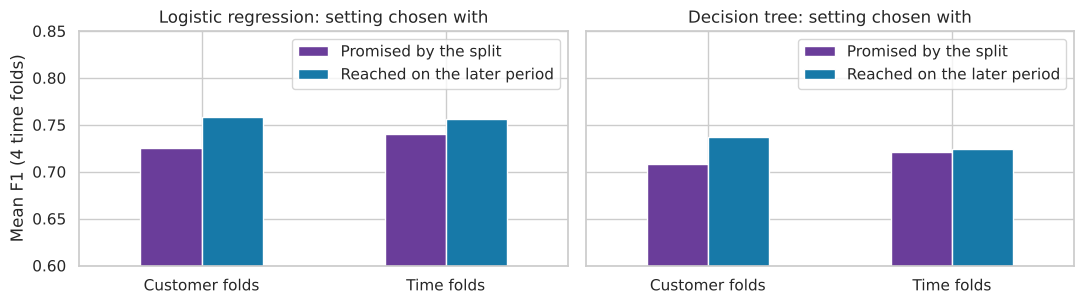

Logistic regression: customer folds promise 0.7253 and reach 0.7582, time folds promise 0.7398 and reach 0.7557
  choice by time folds against choice by customer folds: -0.0025 (tie), better in 1 of 4 folds
Decision tree: customer folds promise 0.7087 and reach 0.7367, time folds promise 0.7210 and reach 0.7238
  choice by time folds against choice by customer folds: -0.0129 (worse), better in 0 of 4 folds


In [6]:
# F1 promised by each kind of fold against the F1 reached on the later period
score_columns = ["Promised by the split", "Reached on the later period"]
split_means = split_scores.groupby(["Model", "Split"])[score_columns].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, model_name in zip(axes, ["Logistic regression", "Decision tree"]):
    split_means.loc[model_name].plot(kind="bar", color=[PLOT_PURPLE, PLOT_BLUE], rot=0, ax=ax)
    ax.set(title=f"{model_name}: setting chosen with", xlabel="", ylabel="Mean F1 (4 time folds)",
           ylim=(0.6, 0.85))
plt.tight_layout()
plt.show()
for model_name in ["Logistic regression", "Decision tree"]:
    later = split_scores[split_scores["Model"] == model_name].pivot(
        index="Fold", columns="Split", values="Reached on the later period")
    result = compare_folds(later["Time folds"], later["Customer folds"])
    means = split_means.loc[model_name]
    print(f"{model_name}: customer folds promise {means.loc['Customer folds', score_columns[0]]:.4f} "
          f"and reach {means.loc['Customer folds', score_columns[1]]:.4f}, time folds promise "
          f"{means.loc['Time folds', score_columns[0]]:.4f} and reach "
          f"{means.loc['Time folds', score_columns[1]]:.4f}")
    print(f"  choice by time folds against choice by customer folds: {result['F1 difference']:+.4f} "
          f"({result['Verdict']}), better in {(later['Time folds'] > later['Customer folds']).sum()} "
          f"of 4 folds")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision</b></p>
<ul>
  <li><b>Estimate</b>: time folds promise an F1 closer to what the chosen setting reaches on the later period (logistic regression: 0.740 promised, 0.756 reached; decision tree: 0.721 and 0.724). Customer folds are further away (0.725 against 0.758, and 0.709 against 0.737)</li>
  <li><b>Choice</b>: the settings chosen with customer folds are not worse on the later period. For the logistic regression the two choices tie (-0.0025), for the decision tree the choice by customer folds is better (time folds -0.0129, in 0 of 4 folds). Inside a small training part the time folds are short, so their choice is less stable</li>
  <li>--> the measured advantage of time folds is the <b>more realistic estimate</b>, not better choices. We keep them because they test what the model is used for: customers with a history at a later time, with a model that has only seen the past. Customer folds test new customers and train on later periods. In the rest of the notebook the time folds use the whole development part, with 1,041 rows in every validation period</li>
</ul>

</div>

<h3>Additional pre-processing</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>Notebook 1 chose the pre-processing from the exploration. Here every choice is tested against other values: each variant changes one choice of the reference (logistic regression on all 40 candidates, C tuned per variant).</p>

</div>

In [7]:
other_flags = prep.ROW_FLAGS + prep.CLIENTES_FLAGS


# undo the 0 of the structural fill, so that the pipeline fills these values itself
def structural_gaps_to_missing(purchases):
    purchases = purchases.copy()
    for col, needed in prep.PURCHASES_NEEDED.items():
        purchases.loc[purchases["prior_purchase_count"] < needed, col] = np.nan
    return purchases


def candidate_pipeline(flags=candidate_flags, **prep_options):
    return prep.build_pipeline(logistic, candidate_numeric, flags, candidate_categorical,
                               **prep_options)


# every variant changes one choice of the reference
variants = {
    "Reference": (candidate_pipeline(), X_dev),
    "Without log1p": (candidate_pipeline(use_log=False), X_dev),
    "MinMaxScaler instead of StandardScaler": (candidate_pipeline(scaler=MinMaxScaler), X_dev),
    "RobustScaler instead of StandardScaler": (candidate_pipeline(scaler=RobustScaler), X_dev),
    "Mean instead of median": (candidate_pipeline(impute="mean"), X_dev),
    "Rare levels: fewer than 10 rows": (candidate_pipeline(min_frequency=10), X_dev),
    "Rare levels: fewer than 100 rows": (candidate_pipeline(min_frequency=100), X_dev),
    "Structural gaps: median instead of 0": (candidate_pipeline(), structural_gaps_to_missing(X_dev)),
    "Without the two structural flags": (candidate_pipeline(flags=other_flags), X_dev),
}
variant_searches = {}
for name, (pipeline, frame) in variants.items():
    search = GridSearchCV(pipeline, C_GRID, cv=inner_folds, scoring=SCORING, refit="f1",
                          return_train_score=True, n_jobs=-1)
    variant_searches[name] = search.fit(frame, y_dev)

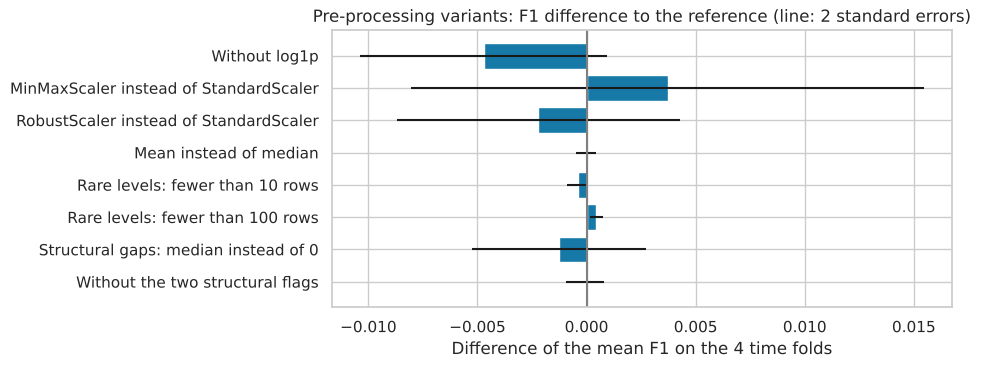

Reference: CV F1 0.7571, CV AUC 0.7983, best C 0.01
Without log1p: -0.0047 (tie), best C 0.01
MinMaxScaler instead of StandardScaler: +0.0037 (tie), best C 0.03
RobustScaler instead of StandardScaler: -0.0022 (tie), best C 0.01
Mean instead of median: -0.0000 (tie), best C 0.01
Rare levels: fewer than 10 rows: -0.0004 (tie), best C 0.01
Rare levels: fewer than 100 rows: +0.0004 (tie), best C 0.01
Structural gaps: median instead of 0: -0.0013 (tie), best C 0.01
Without the two structural flags: -0.0001 (tie), best C 0.01


In [8]:
# every pre-processing variant against the reference on the same folds
reference_search = variant_searches["Reference"]
reference_summary = search_summary(reference_search)
variant_results = pd.DataFrame({
    name: {"Best C": search.best_params_["model__C"],
           **compare_folds(search_folds(search), search_folds(reference_search))}
    for name, search in variant_searches.items() if search is not reference_search}).T

fig, ax = plt.subplots(figsize=(8, 3.6))
shown = variant_results.iloc[::-1]
colors = np.where(shown["Verdict"] == "tie", PLOT_BLUE, PLOT_PURPLE)
ax.barh(shown.index, shown["F1 difference"].astype(float), xerr=2 * shown["SEM"].astype(float),
        color=colors)
ax.axvline(0, color="grey")
ax.set(title="Pre-processing variants: F1 difference to the reference (line: 2 standard errors)",
       xlabel="Difference of the mean F1 on the 4 time folds")
plt.show()
print(f"Reference: CV F1 {reference_summary['CV F1']:.4f}, CV AUC {reference_summary['CV AUC']:.4f}, "
      f"best C {reference_search.best_params_['model__C']}")
for name, row in variant_results.iterrows():
    print(f"{name}: {row['F1 difference']:+.4f} ({row['Verdict']}), best C {row['Best C']}")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision</b>: no variant is better than the reference, so the choices of Notebook 1 stay</p>
<ul>
  <li><b>log1p</b>: without it the F1 is 0.0047 lower, the largest loss of all variants --> kept, it is the one choice that matters</li>
  <li><b>Scaler</b>: MinMaxScaler (+0.0037) and RobustScaler (-0.0022) are ties --> <b>StandardScaler</b> stays, after <b>log1p</b> the columns are roughly symmetric and the L2 penalty then treats all columns alike</li>
  <li><b>Imputation</b>: mean and median give the same score --> median, it is not moved by the remaining outliers</li>
  <li><b>Rare levels</b>: limits of 10, 30 and 100 rows differ by at most 0.0004 --> 30 stays</li>
  <li><b>Structural gaps</b>: the median instead of 0 (-0.0013) and dropping the two flags (-0.0001) change nothing --> the 0 stays, a median would pretend that a first purchase has a typical history. Whether the flags stay is decided by the feature selection</li>
</ul>

</div>

<h2>Feature Selection Strategy and results</h2>

<h3>Strategy</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>Candidates</b>: the 40 variables of Notebook 1 plus <b>random_noise</b> as a benchmark</b>. Identifier-like variables were excluded with evidence in Notebook 1</li>
  <li><b>One method per family from class</b>, on the development part only: a <b>filter</b> (statistics, no model), a <b>wrapper</b> (RFE) and an <b>embedded</b> method (L1 penalty)</li>
  <li><b>Variables, not columns</b>: a categorical variable is kept if at least one of its one-hot columns is kept</li>
  <li><b>Decision rule, fixed in advance</b>: a variable enters the final set with <b>at least 2 of 3 votes</b>. The final set replaces the candidate list if its F1 is not worse</li>
</ul>

</div>

<h3>Method 1: filter</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>A variable passes if its link with the target is significant (p < 0.05; Spearman for numbers and flags, chi-square for categories) and it is not redundant (Spearman of 0.85 or more with a stronger kept variable, the limit that marked the copies in Notebook 1).</p>

</div>

In [9]:
# filter: Spearman for numbers and flags, Cramér's V with the chi-square test for categories
selection_numeric = candidate_numeric + ["random_noise"]
selection_candidates = selection_numeric + candidate_flags + candidate_categorical

relevance = {}
for variable in selection_numeric + candidate_flags:
    rho, p_value = spearmanr(X_dev[variable], y_dev, nan_policy="omit")
    relevance[variable] = {"Measure": "Spearman", "Strength": abs(rho), "p-value": p_value}
for variable in candidate_categorical:
    crosstab = pd.crosstab(X_dev[variable].fillna("missing"), y_dev)
    relevance[variable] = {"Measure": "Cramér's V", "Strength": association(crosstab, method="cramer"),
                           "p-value": chi2_contingency(crosstab).pvalue}
relevance = pd.DataFrame(relevance).T.infer_objects().sort_values("Strength", ascending=False)

In [10]:
# redundancy: go from the strongest to the weakest variable and skip a copy of a kept variable
correlation = X_dev[selection_numeric].corr(method="spearman").abs()
significant = relevance.index[relevance["p-value"] < 0.05]
kept_by_filter, redundant_with = [], {}
for variable in significant:
    twins = [kept for kept in kept_by_filter
             if variable in correlation.index and kept in correlation.index
             and correlation.loc[variable, kept] >= 0.85]
    if twins:
        redundant_with[variable] = twins[0]
    else:
        kept_by_filter.append(variable)

print(f"Filter keeps {len(kept_by_filter)} of {len(selection_candidates)} variables")
print("Not significant:", ", ".join(relevance.index[relevance["p-value"] >= 0.05]))
print("Redundant:", ", ".join(f"{variable} (with {twin})" for variable, twin in redundant_with.items()))

Filter keeps 26 of 41 variables
Not significant: Custo, prior_std_gap_days, Total Portes, random_noise
Redundant: prior_repeat_share (with purchases_per_year), recent_repeat_share (with purchases_per_year), purchase_count_180d (with purchase_count_365d), spend_180d (with spend_365d), spend_90d (with purchase_count_90d), prior_total_spend (with spend_365d), spend_30d (with purchase_count_30d), prior_std_purchase_value (with prior_max_purchase_value), Total Desc_ Linha (with discount_rate), prior_mean_purchase_value (with prior_max_purchase_value), Total Liquido (with Total Imp_)


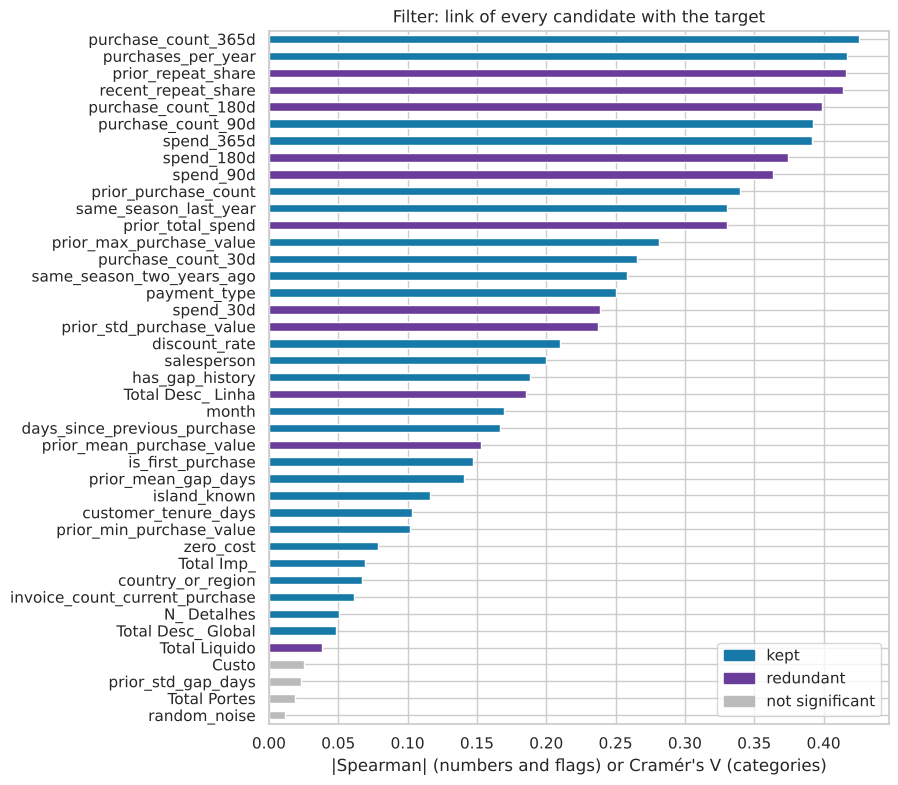

In [11]:
# strength of every variable, coloured by the decision of the filter
status = pd.Series("kept", index=relevance.index)
status[relevance["p-value"] >= 0.05] = "not significant"
status[list(redundant_with)] = "redundant"
status_colors = {"kept": PLOT_BLUE, "redundant": PLOT_PURPLE, "not significant": "#BBBBBB"}

ax = relevance["Strength"][::-1].plot(kind="barh", color=status.map(status_colors)[::-1],
                                      figsize=(8, 9))
ax.legend(handles=[Patch(color=color, label=label) for label, color in status_colors.items()],
          loc="lower right")
ax.set(title="Filter: link of every candidate with the target",
       xlabel="|Spearman| (numbers and flags) or Cramér's V (categories)", ylabel="")
plt.show()

<h3>Method 2: wrapper (RFE)</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>RFE with a logistic regression removes the weakest column step by step. It is a step of the pipeline, so the columns are chosen again in every fold (no selection bias), and the number of columns is tuned from 10 to 50.</p>

</div>

In [12]:
# wrapper: RFE inside the pipeline, the number of columns is tuned on the time folds
reference_C = reference_search.best_params_["model__C"]
selection_preprocessor = prep.build_preprocessor(selection_numeric, candidate_flags,
                                                 candidate_categorical)
n_columns = selection_preprocessor.fit(X_dev).get_feature_names_out().size

rfe_pipeline = Pipeline([
    ("prep", selection_preprocessor),
    ("select", RFE(LogisticRegression(C=reference_C, max_iter=5000))),
    ("model", LogisticRegression(C=reference_C, max_iter=5000)),
])
rfe_search = grid_search(rfe_pipeline, {"select__n_features_to_select": [10, 15, 20, 25, 30, 40, 50]})

In [13]:
# variables behind the columns that RFE keeps
encoded_names = rfe_search.best_estimator_["prep"].get_feature_names_out()
encoded_variable = np.array([prep.source_variable(name, candidate_categorical) for name in encoded_names])
kept_by_rfe = sorted(set(encoded_variable[rfe_search.best_estimator_["select"].support_].tolist()))
print(f"Best number of columns: {rfe_search.best_params_['select__n_features_to_select']} of {n_columns}, "
      f"they belong to {len(kept_by_rfe)} variables")

Best number of columns: 20 of 66, they belong to 15 variables


<h3>Method 3: embedded (L1 penalty)</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>A logistic regression with L1 penalty sets the coefficients of weak columns to exactly 0. Six values of C are tested, the variables with a coefficient other than 0 are kept.</p>

</div>

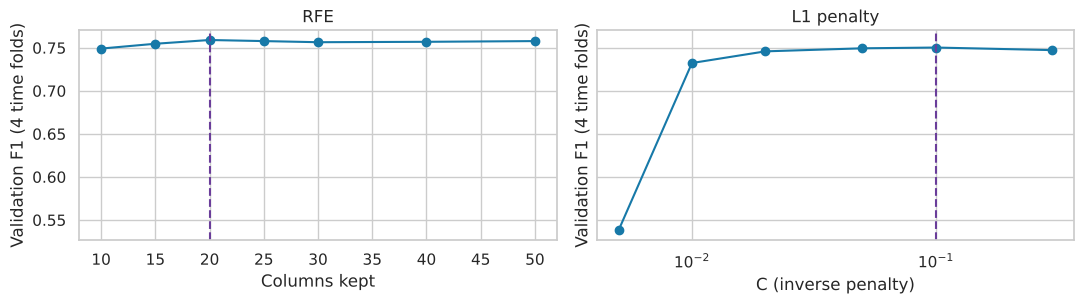

RFE: best F1 0.7590, lowest F1 of the tested values 0.7491
L1: best F1 0.7503 with C = 0.1, 33 of 66 coefficients are not 0 (26 variables)


In [14]:
l1_pipeline = Pipeline([
    ("prep", selection_preprocessor),
    ("model", LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=5000,
                                 random_state=RANDOM_STATE)),
])
l1_search = grid_search(l1_pipeline, {"model__C": [0.005, 0.01, 0.02, 0.05, 0.1, 0.3]})
l1_coefficients = l1_search.best_estimator_["model"].coef_[0]
kept_by_l1 = sorted(set(encoded_variable[l1_coefficients != 0].tolist()))

# the values tested for the wrapper and the embedded method, the dashed line marks the best one
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
searched = [(rfe_search, "select__n_features_to_select", "RFE", "Columns kept"),
            (l1_search, "model__C", "L1 penalty", "C (inverse penalty)")]
for ax, (search, parameter, title, label) in zip(axes, searched):
    curve = pd.DataFrame(search.cv_results_).set_index(f"param_{parameter}")
    ax.plot(curve.index, curve["mean_test_f1"], marker="o", color=PLOT_BLUE)
    ax.axvline(search.best_params_[parameter], color=PLOT_PURPLE, linestyle="--")
    ax.set(title=title, xlabel=label, ylabel="Validation F1 (4 time folds)")
axes[1].set_xscale("log")
plt.tight_layout()
plt.show()
print(f"RFE: best F1 {rfe_search.best_score_:.4f}, lowest F1 of the tested values "
      f"{rfe_search.cv_results_['mean_test_f1'].min():.4f}")
print(f"L1: best F1 {l1_search.best_score_:.4f} with C = {l1_search.best_params_['model__C']}, "
      f"{(l1_coefficients != 0).sum()} of {n_columns} coefficients are not 0 "
      f"({len(kept_by_l1)} variables)")

<h3>Results: the vote and the final feature set</h3>

In [15]:
# one vote per method for every variable
votes = pd.DataFrame({
    "Filter": [variable in kept_by_filter for variable in selection_candidates],
    "RFE": [variable in kept_by_rfe for variable in selection_candidates],
    "L1": [variable in kept_by_l1 for variable in selection_candidates],
}, index=selection_candidates)
votes["Votes"] = votes.sum(axis=1)
votes["Final set"] = votes["Votes"] >= 2

final_variables = votes.index[votes["Final set"]].tolist()
FINAL_NUMERIC = [variable for variable in final_variables if variable in candidate_numeric]
FINAL_FLAGS = [variable for variable in final_variables if variable in candidate_flags]
FINAL_CATEGORICAL = [variable for variable in final_variables if variable in candidate_categorical]

for n_votes in [3, 2, 1, 0]:
    with_n_votes = votes.index[votes["Votes"] == n_votes]
    print(f"{n_votes} votes ({len(with_n_votes)}):", ", ".join(with_n_votes))
noise_votes = votes.loc["random_noise", ["Filter", "RFE", "L1"]]
print(f"\nFinal set: {len(final_variables)} of {len(selection_candidates) - 1} candidate variables")
print("random_noise is kept by:", ", ".join(noise_votes.index[noise_votes]) or "no method")

3 votes (12): Total Imp_, customer_tenure_days, prior_mean_gap_days, purchase_count_90d, purchase_count_365d, discount_rate, same_season_last_year, same_season_two_years_ago, zero_cost, island_known, salesperson, month
2 votes (9): Total Desc_ Global, N_ Detalhes, invoice_count_current_purchase, prior_std_purchase_value, prior_max_purchase_value, purchase_count_180d, prior_repeat_share, payment_type, country_or_region
1 votes (13): Total Desc_ Linha, days_since_previous_purchase, prior_purchase_count, prior_std_gap_days, prior_min_purchase_value, purchase_count_30d, spend_30d, spend_90d, spend_365d, purchases_per_year, random_noise, is_first_purchase, has_gap_history
0 votes (7): Total Liquido, Total Portes, Custo, prior_total_spend, prior_mean_purchase_value, spend_180d, recent_repeat_share

Final set: 21 of 40 candidate variables
random_noise is kept by: L1


In [16]:
# split a list of variables into numeric, flag and categorical variables
def variable_lists(variables):
    return ([variable for variable in variables if variable in selection_numeric],
            [variable for variable in variables if variable in candidate_flags],
            [variable for variable in variables if variable in candidate_categorical])


# the single methods and three vote limits, to see what the limit of 2 votes costs
feature_sets = {
    "All 40 candidates": candidate_numeric + candidate_flags + candidate_categorical,
    "Filter": kept_by_filter,
    "RFE": kept_by_rfe,
    "L1": kept_by_l1,
    "1 vote or more": votes.index[votes["Votes"] >= 1].tolist(),
    "2 votes or more (final set)": final_variables,
    "3 votes": votes.index[votes["Votes"] == 3].tolist(),
}
set_searches = {name: grid_search(prep.build_pipeline(logistic, *variable_lists(variables)), C_GRID)
                for name, variables in feature_sets.items()}
set_scores = pd.DataFrame({name: search_summary(search) for name, search in set_searches.items()}).T

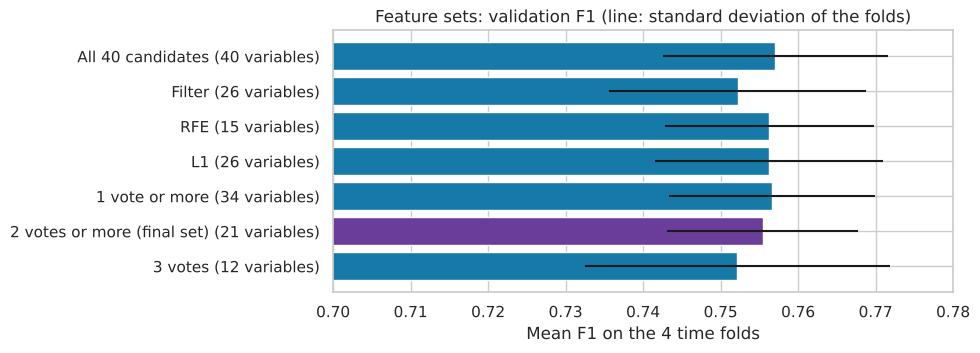

All 40 candidates: 40 variables, CV F1 0.7571, CV AUC 0.7983, best C 0.01, against all candidates +0.0000 (tie)
Filter: 26 variables, CV F1 0.7522, CV AUC 0.7956, best C 0.01, against all candidates -0.0049 (tie)
RFE: 15 variables, CV F1 0.7563, CV AUC 0.8005, best C 0.01, against all candidates -0.0008 (tie)
L1: 26 variables, CV F1 0.7563, CV AUC 0.7986, best C 0.01, against all candidates -0.0008 (tie)
1 vote or more: 34 variables, CV F1 0.7566, CV AUC 0.7983, best C 0.01, against all candidates -0.0005 (tie)
2 votes or more (final set): 21 variables, CV F1 0.7554, CV AUC 0.8009, best C 0.003, against all candidates -0.0016 (tie)
3 votes: 12 variables, CV F1 0.7522, CV AUC 0.7954, best C 0.01, against all candidates -0.0049 (tie)


In [17]:
# validation F1 of the feature sets
labels = [f"{name} ({len(feature_sets[name])} variables)" for name in set_scores.index]
colors = [PLOT_PURPLE if "final" in name else PLOT_BLUE for name in set_scores.index]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(labels[::-1], set_scores["CV F1"][::-1], xerr=set_scores["CV F1 std"][::-1], color=colors[::-1])
ax.set(title="Feature sets: validation F1 (line: standard deviation of the folds)",
       xlabel="Mean F1 on the 4 time folds", xlim=(0.70, 0.78))
plt.show()

all_candidates_folds = search_folds(set_searches["All 40 candidates"])
for name, search in set_searches.items():
    result = compare_folds(search_folds(search), all_candidates_folds)
    print(f"{name}: {len(feature_sets[name])} variables, CV F1 {set_scores.loc[name, 'CV F1']:.4f}, "
          f"CV AUC {set_scores.loc[name, 'CV AUC']:.4f}, best C {search.best_params_['model__C']}, "
          f"against all candidates {result['F1 difference']:+.4f} ({result['Verdict']})")

In [18]:
# does the final set also work for a model that is not linear?
forest = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=RANDOM_STATE)
forest_folds = {}
for name in ["All 40 candidates", "2 votes or more (final set)"]:
    forest_pipeline = prep.build_pipeline(forest, *variable_lists(feature_sets[name]))
    scores = cross_validate(forest_pipeline, X_dev, y_dev, cv=inner_folds, scoring=SCORING, n_jobs=-1)
    forest_folds[name] = scores["test_f1"]
forest_result = compare_folds(forest_folds["2 votes or more (final set)"],
                              forest_folds["All 40 candidates"])
print(f"Random forest, CV F1 with all 40 candidates: {forest_folds['All 40 candidates'].mean():.4f}, "
      f"with the final set: {forest_folds['2 votes or more (final set)'].mean():.4f} "
      f"({forest_result['F1 difference']:+.4f}, {forest_result['Verdict']})")

Random forest, CV F1 with all 40 candidates: 0.7542, with the final set: 0.7507 (-0.0035, tie)


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Results</b></p>
<ul>
  <li><b>Filter</b> keeps 26 variables: 4 are not significant (among them <b>random_noise</b>), 11 are copies of a stronger variable</li>
  <li><b>RFE</b> is best with 20 columns (F1 0.7590), which belong to 15 variables. The other tested numbers of columns give 0.749 to 0.758</li>
  <li><b>L1</b> is best with C = 0.1 and keeps 26 variables, <b>among them <b>random_noise</b> --> one method alone is not reliable, which is the reason for the vote</li>
  <li><b>Vote</b>: 12 variables get 3 votes and 9 get 2 --> <b>final set of 21 of the 40 candidates</b>, <b>random_noise</b> is out</li>
  <li><b>Vote limit</b>: 1 vote keeps 34 variables (F1 0.7566), 2 votes 21 (0.7554), 3 votes 12 (0.7522). All tie with the 40 candidates (0.7571), but 3 votes lose the most --> 2 votes is the smallest set without a visible loss</li>
  <li><b>Dropped</b> (19): the four spend windows and <b>purchase_count_30d</b>, nine supplied history and invoice columns that copy a kept variable or have no signal, and <b>days_since_previous_purchase</b>, <b>purchases_per_year</b>, <b>recent_repeat_share</b> and the two structural flags. Their information is in the kept counts and <b>prior_repeat_share</b></li>
  <li>The final set also ties for a random forest (0.7507 against 0.7542), so it is not only good for linear models</li>
  <li><b>Decision</b>: a tie means the smaller set wins --> <b>all models below and the final model use the 21 selected variables</b>. The filter and the vote saw all development rows, so 0.7554 is slightly optimistic. The holdout at the end has seen nothing</li>
</ul>

</div>

<h2>Optimization efforts: presentation, results and discussion</h2>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>Eight algorithms are tuned on the same 4 time folds and the 21 selected variables.</p>
<ul>
  <li><b>Grid search</b> for the models with few hyperparameters: logistic regression (<b>C</b>), Gaussian Naive Bayes (<b>var_smoothing</b>), kNN (<b>n_neighbors</b>, <b>weights</b>), decision tree (<b>max_depth</b>, <b>min_samples_leaf</b>, <b>ccp_alpha</b>)</li>
  <li><b>Random search with 60 settings</b> for random forest, gradient boosting and the neural network: a full grid would need thousands of fits, and 60 random settings contain one of the best 5% with a chance of 95% (1 - 0.95^60)</li>
  <li><b>Voting</b>: soft vote of the tuned logistic regression, random forest and gradient boosting</li>
</ul>

</div>

<h3>Default settings</h3>

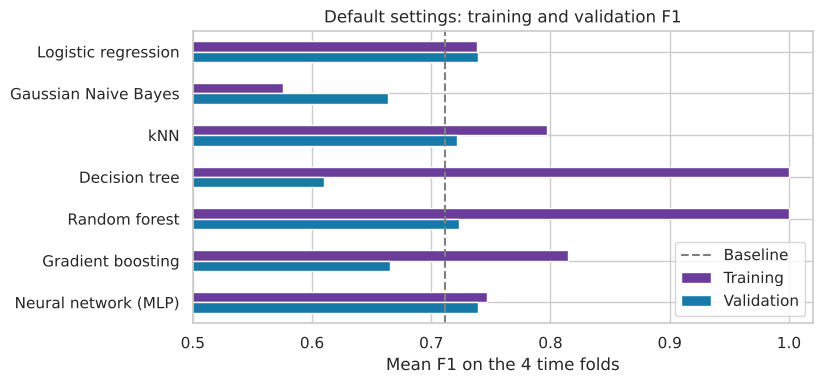

Logistic regression: training 0.738, validation 0.739
Gaussian Naive Bayes: training 0.576, validation 0.664
kNN: training 0.797, validation 0.721
Decision tree: training 1.000, validation 0.610
Random forest: training 1.000, validation 0.723
Gradient boosting: training 0.815, validation 0.665
Neural network (MLP): training 0.747, validation 0.739


In [19]:
def model_pipeline(model):
    return prep.build_pipeline(model, FINAL_NUMERIC, FINAL_FLAGS, FINAL_CATEGORICAL)


# training and validation scores of one pipeline on the inner folds
def cross_validated_row(pipeline):
    scores = cross_validate(pipeline, X_dev, y_dev, cv=inner_folds, scoring=SCORING,
                            return_train_score=True, n_jobs=-1)
    row = {"Train F1": scores["train_f1"].mean(), "CV F1": scores["test_f1"].mean(),
           "CV F1 std": scores["test_f1"].std(), "CV AUC": scores["test_auc"].mean()}
    return row, scores["test_f1"]


default_models = {
    "Logistic regression": LogisticRegression(max_iter=5000),
    "Gaussian Naive Bayes": GaussianNB(),
    "kNN": KNeighborsClassifier(),
    "Decision tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Gradient boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "Neural network (MLP)": MLPClassifier(max_iter=1000, early_stopping=True,
                                          random_state=RANDOM_STATE),
}
default_scores = pd.DataFrame({name: cross_validated_row(model_pipeline(model))[0]
                               for name, model in default_models.items()}).T

shown = default_scores.rename(columns={"Train F1": "Training", "CV F1": "Validation"})
ax = shown[["Training", "Validation"]].plot(kind="barh", color=[PLOT_PURPLE, PLOT_BLUE], figsize=(8, 3.8))
ax.axvline(baseline_folds.mean(), color="grey", linestyle="--", label="Baseline")
ax.invert_yaxis()
ax.set(title="Default settings: training and validation F1", xlabel="Mean F1 on the 4 time folds",
       xlim=(0.5, 1.02))
ax.legend(loc="lower right")
plt.show()
for name, row in default_scores.iterrows():
    print(f"{name}: training {row['Train F1']:.3f}, validation {row['CV F1']:.3f}")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li><b>Decision tree and random forest overfit</b>: training F1 1.000, validation 0.610 and 0.723. Their trees grow until every leaf is pure and learn the training period by heart. Gradient boosting (0.815 against 0.665) and kNN with 5 neighbours (0.797 against 0.721) overfit less</li>
  <li>Only the logistic regression and the neural network (both 0.739) are clearly above the baseline (0.712), Naive Bayes is below it (0.664)</li>
  <li>--> default settings say little about a model, every model gets its own search</li>
</ul>

</div>

<h3>Grid search: models with few hyperparameters</h3>

In [20]:
# best hyperparameters of a search as one short text
def short_setting(search):
    parts = []
    for name, value in search.best_params_.items():
        value = round(float(value), 4) if isinstance(value, float) else value
        parts.append(f"{name.replace('model__', '')}={value}")
    return ", ".join(parts)


grids = {
    "Logistic regression": (LogisticRegression(max_iter=5000),
                            {"model__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 10]}),
    "Gaussian Naive Bayes": (GaussianNB(),
                             {"model__var_smoothing": [1e-9, 1e-3, 1e-2, 1e-1, 1]}),
    "kNN": (KNeighborsClassifier(),
            {"model__n_neighbors": [5, 15, 30, 60, 100, 150, 200],
             "model__weights": ["uniform", "distance"]}),
    "Decision tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
                      {"model__max_depth": [2, 3, 4, 6, 8, 12, None],
                       "model__min_samples_leaf": [1, 25, 50, 100],
                       "model__ccp_alpha": [0, 0.001, 0.002]}),
}
searches = {name: grid_search(model_pipeline(model), grid) for name, (model, grid) in grids.items()}

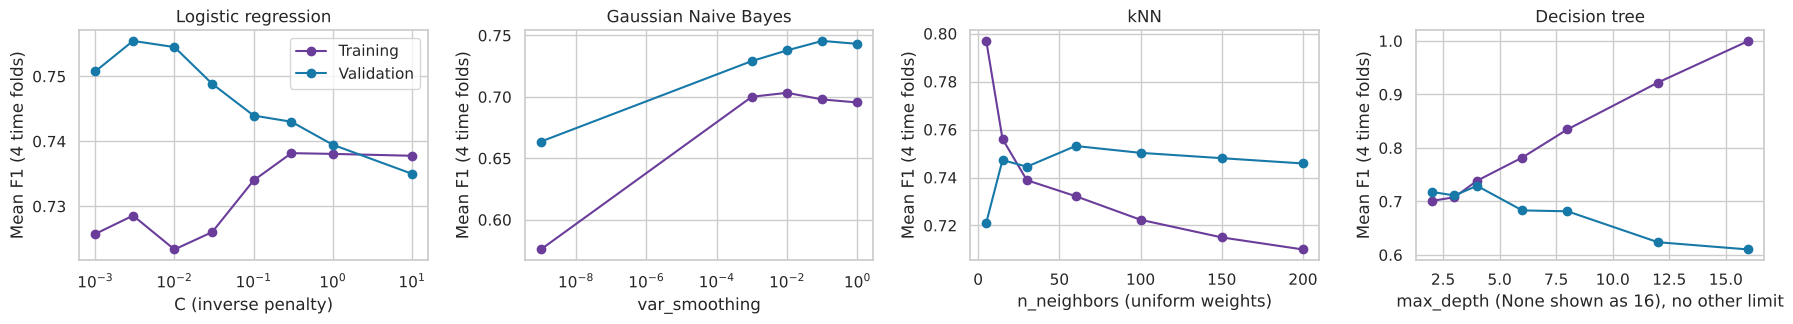

Logistic regression: 8 settings, best: C=0.003, training 0.729, validation 0.7554
  validation F1 along the curve: {0.001: 0.751, 0.003: 0.755, 0.01: 0.754, 0.03: 0.749, 0.1: 0.744, 0.3: 0.743, 1.0: 0.739, 10.0: 0.735}
Gaussian Naive Bayes: 5 settings, best: var_smoothing=0.1, training 0.698, validation 0.7455
  validation F1 along the curve: {1e-09: 0.664, 0.001: 0.729, 0.01: 0.738, 0.1: 0.746, 1.0: 0.743}
kNN: 14 settings, best: n_neighbors=60, weights=distance, training 1.000, validation 0.7533
  validation F1 along the curve: {5.0: 0.721, 15.0: 0.747, 30.0: 0.745, 60.0: 0.753, 100.0: 0.75, 150.0: 0.748, 200.0: 0.746}
Decision tree: 84 settings, best: ccp_alpha=0, max_depth=4, min_samples_leaf=50, training 0.732, validation 0.7350
  validation F1 along the curve: {2.0: 0.718, 3.0: 0.711, 4.0: 0.729, 6.0: 0.683, 8.0: 0.682, 12.0: 0.624, 16.0: 0.61}


In [21]:
# one hyperparameter per model, the others are held fixed so that the curve shows only its effect
panels = [("Logistic regression", "param_model__C", "C (inverse penalty)", {}),
          ("Gaussian Naive Bayes", "param_model__var_smoothing", "var_smoothing", {}),
          ("kNN", "param_model__n_neighbors", "n_neighbors (uniform weights)",
           {"param_model__weights": "uniform"}),
          ("Decision tree", "param_model__max_depth", "max_depth (None shown as 16), no other limit",
           {"param_model__min_samples_leaf": 1, "param_model__ccp_alpha": 0})]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.4))
tested_values = {}
for ax, (name, parameter, label, fixed) in zip(axes, panels):
    results = pd.DataFrame(searches[name].cv_results_)
    for fixed_parameter, fixed_value in fixed.items():
        results = results[results[fixed_parameter] == fixed_value]
    results[parameter] = results[parameter].fillna(16).astype(float)
    curve = results.set_index(parameter).sort_index()
    ax.plot(curve.index, curve["mean_train_f1"], marker="o", color=PLOT_PURPLE, label="Training")
    ax.plot(curve.index, curve["mean_test_f1"], marker="o", color=PLOT_BLUE, label="Validation")
    if name in ["Logistic regression", "Gaussian Naive Bayes"]:
        ax.set_xscale("log")
    ax.set(title=name, xlabel=label, ylabel="Mean F1 (4 time folds)")
    tested_values[name] = curve["mean_test_f1"].round(3).to_dict()
axes[0].legend()
plt.tight_layout()
plt.show()
for name, search in searches.items():
    summary = search_summary(search)
    print(f"{name}: {len(search.cv_results_['params'])} settings, best: {short_setting(search)}, "
          f"training {summary['Train F1']:.3f}, validation {summary['CV F1']:.4f}")
    print("  validation F1 along the curve:", tested_values[name])

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Results and discussion</b></p>
<ul>
  <li><b>Logistic regression</b>: best at C = 0.003 (0.7554). Weaker penalties are lower (0.735 at C = 10) although the training F1 rises (0.729 to 0.738), so a weak penalty fits patterns of old periods. C = 0.001 is lower again (0.751), so the best value is not at the edge of the grid</li>
  <li><b>Gaussian Naive Bayes</b>: the default smoothing (1e-9) gives 0.664, below the baseline. 0.1 is best (0.7455), 1 is lower again (0.743)</li>
  <li><b>kNN</b>: 5 neighbours overfit (training 0.797, validation 0.721), 200 underfit slightly (0.746), 60 is best (0.753). With distance weights the training F1 is always 1, because every row is its own nearest neighbour, so for kNN only the validation score counts</li>
  <li><b>Decision tree</b>: without another limit the training F1 rises to 1.000 with the depth while the validation F1 falls from 0.729 (depth 4) to 0.610 --> the textbook picture of overfitting. The best tree has depth 4 and at least 50 rows per leaf (0.735)</li>
</ul>

</div>

<h3>Random forest: parameter by parameter, then a random search</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>The default forest grows every tree until its leaves are pure. Before the joint search we look at the two parameters that limit the trees, one at a time.</p>

</div>

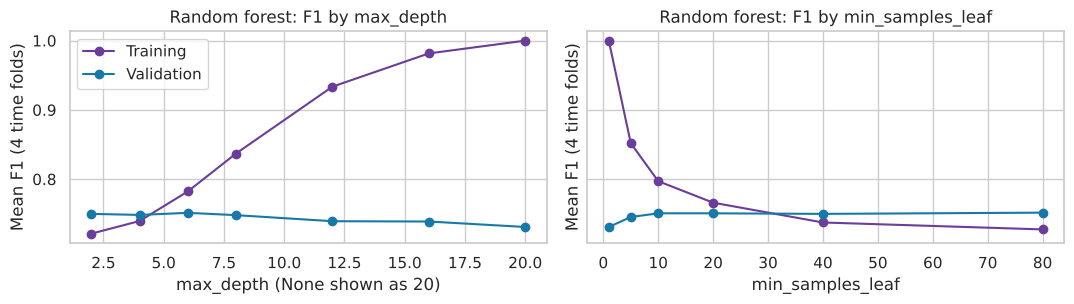

max_depth, training F1: {2: 0.721, 4: 0.74, 6: 0.782, 8: 0.837, 12: 0.934, 16: 0.982, None: 1.0}
max_depth, validation F1: {2: 0.75, 4: 0.748, 6: 0.751, 8: 0.748, 12: 0.739, 16: 0.739, None: 0.731}
min_samples_leaf, training F1: {1: 1.0, 5: 0.852, 10: 0.797, 20: 0.766, 40: 0.737, 80: 0.727}
min_samples_leaf, validation F1: {1: 0.731, 5: 0.745, 10: 0.751, 20: 0.751, 40: 0.75, 80: 0.752}


In [22]:
# random forest: one hyperparameter at a time, the others stay at their default
default_forest = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
depth_search = grid_search(model_pipeline(default_forest),
                           {"model__max_depth": [2, 4, 6, 8, 12, 16, None]})
leaf_search = grid_search(model_pipeline(default_forest),
                          {"model__min_samples_leaf": [1, 5, 10, 20, 40, 80]})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
panels = [(depth_search, "param_model__max_depth", "max_depth (None shown as 20)"),
          (leaf_search, "param_model__min_samples_leaf", "min_samples_leaf")]
for ax, (search, parameter, label) in zip(axes, panels):
    curve = pd.DataFrame(search.cv_results_)
    values = curve[parameter].fillna(20).astype(float)
    ax.plot(values, curve["mean_train_f1"], marker="o", color=PLOT_PURPLE, label="Training")
    ax.plot(values, curve["mean_test_f1"], marker="o", color=PLOT_BLUE, label="Validation")
    ax.set(title=f"Random forest: F1 by {label.split(' ')[0]}", xlabel=label,
           ylabel="Mean F1 (4 time folds)")
axes[0].legend()
plt.tight_layout()
plt.show()
for search, parameter, _ in panels:
    curve = pd.DataFrame(search.cv_results_).set_index(parameter)
    name = parameter.replace("param_model__", "")
    print(f"{name}, training F1:", curve["mean_train_f1"].round(3).to_dict())
    print(f"{name}, validation F1:", curve["mean_test_f1"].round(3).to_dict())

In [23]:
# random search: 60 random settings per model, same folds and random_state
N_SETTINGS = 60


def random_search(pipeline, distributions):
    search = RandomizedSearchCV(pipeline, distributions, n_iter=N_SETTINGS, cv=inner_folds,
                                scoring=SCORING, refit="f1", return_train_score=True,
                                random_state=RANDOM_STATE, n_jobs=-1)
    return search.fit(X_dev, y_dev)


searches["Random forest"] = random_search(
    model_pipeline(RandomForestClassifier(random_state=RANDOM_STATE)),
    {"model__n_estimators": randint(100, 401),
     "model__max_depth": randint(3, 13),
     "model__min_samples_leaf": randint(5, 81),
     "model__max_features": uniform(0.1, 0.6)})

<h3>Gradient boosting and neural network</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>Both get the same kind of random search. The ranges are wide on purpose (learning rate from 0.01 to 0.3, penalty <b>alpha</b> from 0.001 to 10), so that the search can show at which end the good settings lie.</p>

</div>

In [24]:
# same search for gradient boosting
searches["Gradient boosting"] = random_search(
    model_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE)),
    {"model__n_estimators": randint(50, 301),
     "model__learning_rate": loguniform(0.01, 0.3),
     "model__max_depth": randint(1, 5),
     "model__subsample": uniform(0.5, 0.5),
     "model__min_samples_leaf": randint(5, 81)})

In [25]:
# same search for the neural network
searches["Neural network (MLP)"] = random_search(
    model_pipeline(MLPClassifier(max_iter=1000, early_stopping=True, random_state=RANDOM_STATE)),
    {"model__hidden_layer_sizes": [(8,), (16,), (32,), (16, 8), (32, 16)],
     "model__alpha": loguniform(1e-3, 10),
     "model__learning_rate_init": loguniform(1e-4, 1e-2)})

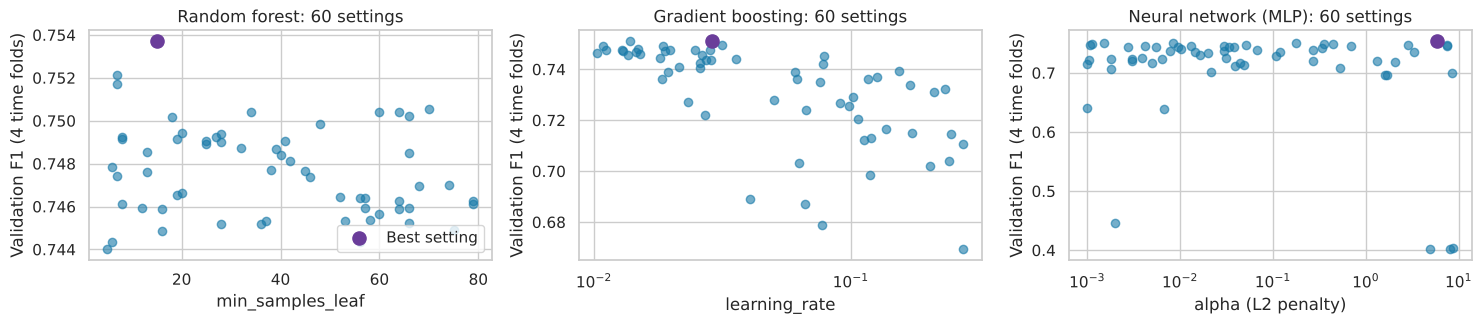

Random forest: validation F1 of the 60 settings from 0.744 to 0.754, best: max_depth=10, max_features=0.1033, min_samples_leaf=15, n_estimators=180 (training 0.762)
Gradient boosting: validation F1 of the 60 settings from 0.669 to 0.751, best: learning_rate=0.0289, max_depth=2, min_samples_leaf=58, n_estimators=155, subsample=0.7839 (training 0.742)
Neural network (MLP): validation F1 of the 60 settings from 0.401 to 0.754, best: alpha=5.9076, hidden_layer_sizes=(32,), learning_rate_init=0.0025 (training 0.729)


In [26]:
# every dot is one of the 60 settings of a random search, the best one is marked
shown = [("Random forest", "param_model__min_samples_leaf", "min_samples_leaf"),
         ("Gradient boosting", "param_model__learning_rate", "learning_rate"),
         ("Neural network (MLP)", "param_model__alpha", "alpha (L2 penalty)")]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, (name, parameter, label) in zip(axes, shown):
    results = pd.DataFrame(searches[name].cv_results_)
    best = searches[name].best_index_
    ax.scatter(results[parameter].astype(float), results["mean_test_f1"], color=PLOT_BLUE, alpha=0.6)
    ax.scatter(float(results.loc[best, parameter]), results.loc[best, "mean_test_f1"],
               color=PLOT_PURPLE, s=90, label="Best setting")
    if name != "Random forest":
        ax.set_xscale("log")
    ax.set(title=f"{name}: 60 settings", xlabel=label, ylabel="Validation F1 (4 time folds)")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()
for name, _, _ in shown:
    summary = search_summary(searches[name])
    tested = searches[name].cv_results_["mean_test_f1"]
    print(f"{name}: validation F1 of the 60 settings from {tested.min():.3f} to {tested.max():.3f}, "
          f"best: {short_setting(searches[name])} (training {summary['Train F1']:.3f})")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Results and discussion</b></p>
<ul>
  <li><b>Random forest</b>: the default forest overfits (training 1.000, validation 0.731). A depth of 8 or less, or 10 or more rows per leaf, lifts the validation F1 to about 0.75 and lowers the training F1 (0.837 at depth 8, 0.797 with 10 rows per leaf). The random search stays in this region, and all 60 settings lie between 0.744 and 0.754 --> once the trees are limited, the forest is not sensitive. Best: depth 10, 15 rows per leaf, 10% of the columns per split. Training 0.762 against validation 0.754 --> the tuned forest <b>no longer overfits</b></li>
  <li><b>Gradient boosting</b>: the 60 settings range from 0.669 to 0.751, and the F1 falls as the learning rate grows. Best: learning rate 0.029 with trees of depth 2</li>
  <li><b>Neural network</b>: the widest range (0.401 to 0.754). Best: one hidden layer of 32 units with a strong penalty (alpha 5.9)</li>
  <li><b>Common pattern</b>: every model is best at its regularised end --> the data rewards simple models</li>
  <li>A training F1 <i>below</i> the validation F1 (logistic regression 0.729 against 0.755) is not an error: the F1 depends on the repeat rate of the period, and the training rows include the early years</li>
</ul>

</div>

<h3>Voting</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>The soft vote averages the probabilities of three tuned models that work in different ways: a linear model, bagged trees and boosted trees.</p>

</div>

In [27]:
# soft voting: mean probability of three tuned models
voting = VotingClassifier(
    estimators=[(key, clone(searches[name].best_estimator_["model"]))
                for key, name in [("logistic", "Logistic regression"), ("forest", "Random forest"),
                                  ("boosting", "Gradient boosting")]],
    voting="soft")
voting_row, voting_folds = cross_validated_row(model_pipeline(voting))
print(f"Voting: training {voting_row['Train F1']:.3f}, validation {voting_row['CV F1']:.4f}, "
      f"AUC {voting_row['CV AUC']:.4f}")

Voting: training 0.742, validation 0.7544, AUC 0.8016


<h2>Comparison of performance between candidate models</h2>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>All tuned models side by side: best setting, training F1, validation F1 with the standard deviation of the folds, AUC and the comparison with the best model.</p>

</div>

In [28]:
# best setting and scores of every tuned model, compared with the best one fold by fold
comparison = {"Always a repeat (baseline)": {"Best setting": "-", "CV F1": baseline_folds.mean(),
                                             "CV F1 std": baseline_folds.std(), "CV AUC": 0.5}}
fold_scores = {}
for name, search in searches.items():
    comparison[name] = {"Best setting": short_setting(search), **search_summary(search)}
    fold_scores[name] = search_folds(search)
comparison["Voting"] = {"Best setting": "soft vote of 3 tuned models", **voting_row}
fold_scores["Voting"] = voting_folds

comparison = pd.DataFrame(comparison).T.infer_objects()
comparison["Train - CV"] = comparison["Train F1"] - comparison["CV F1"]
comparison = comparison.sort_values("CV F1", ascending=False)
best_model_name = comparison.index[0]
for name, scores in fold_scores.items():
    if name != best_model_name:
        result = compare_folds(scores, fold_scores[best_model_name])
        verdict = f"{result['F1 difference']:+.4f} ({result['Verdict']})"
        comparison.loc[name, "Compared with the best"] = verdict
shown_columns = ["Best setting", "Train F1", "CV F1", "CV F1 std", "Train - CV", "CV AUC",
                 "Compared with the best"]
comparison[shown_columns].round(4).fillna("")

,Best setting,Train F1,CV F1,CV F1 std,Train - CV,CV AUC,Compared with the best
Logistic regression,C=0.003,0.7286,0.7554,0.0123,-0.0269,0.8009,
Voting,soft vote of 3 tuned models,0.7422,0.7544,0.0171,-0.0122,0.8016,-0.0010 (tie)
Neural network (MLP),"alpha=5.9076, hidden_layer_sizes=(32,), learning_rate_init=0.0025",0.7286,0.7540,0.0140,-0.0254,0.7969,-0.0015 (tie)
Random forest,"max_depth=10, max_features=0.1033, min_samples_leaf=15, n_estimators=180",0.762,0.7537,0.0151,0.0083,0.7980,-0.0017 (tie)
kNN,"n_neighbors=60, weights=distance",1.0,0.7533,0.0187,0.2467,0.7943,-0.0022 (tie)
Gradient boosting,"learning_rate=0.0289, max_depth=2, min_samples_leaf=58, n_estimators=155, subsample=0....",0.7418,0.7511,0.0159,-0.0094,0.7923,-0.0043 (tie)
Gaussian Naive Bayes,var_smoothing=0.1,0.6979,0.7455,0.0137,-0.0476,0.7849,-0.0099 (tie)
Decision tree,"ccp_alpha=0, max_depth=4, min_samples_leaf=50",0.7315,0.7350,0.0227,-0.0035,0.7632,-0.0204 (tie)
Always a repeat (baseline),-,,0.7116,0.0281,,0.5000,


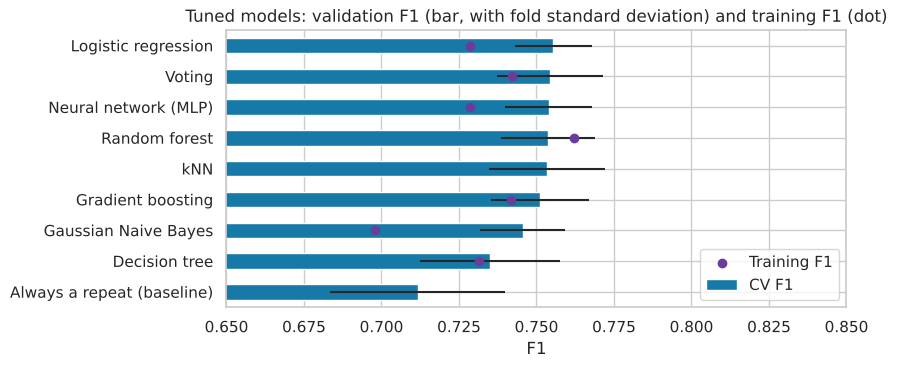

In [29]:
# validation F1 as bar, training F1 as dot
ax = comparison["CV F1"].sort_values().plot(kind="barh", xerr=comparison["CV F1 std"].reindex(
    comparison["CV F1"].sort_values().index), color=PLOT_BLUE, figsize=(8, 3.6))
ax.scatter(comparison["Train F1"].reindex(comparison["CV F1"].sort_values().index),
           range(len(comparison)), color=PLOT_PURPLE, zorder=3, label="Training F1")
ax.set(title="Tuned models: validation F1 (bar, with fold standard deviation) and training F1 (dot)",
       xlabel="F1", ylabel="", xlim=(0.65, 0.85))
ax.legend(loc="lower right")
plt.show()

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision</b></p>
<ul>
  <li><b>All 8 tuned models beat the baseline</b> (0.7116), from 0.7350 for the decision tree to 0.7554 for the logistic regression</li>
  <li>The first five are within <b>0.0022 F1</b> (logistic regression, voting, neural network, random forest, kNN) --> ties. The ensembles do not beat the linear model: voting has the best AUC (0.8016 against 0.8009) but not the best F1</li>
  <li>Naive Bayes (-0.0099) and the tree (-0.0204) are lower, but with 4 folds their differences vary so much that the rule still says tie --> the rule is careful, a tie is not a proof that two models are equal</li>
  <li><b>Decision: logistic regression, L2 penalty, C = 0.003</b>: best mean F1, smallest spread between the folds (0.0123), and in a tie the simpler model wins. Its coefficients can be read and explained (Notebook 3), and it can not memorise customers</li>
</ul>

</div>

<h3>Threshold of the chosen model</h3>

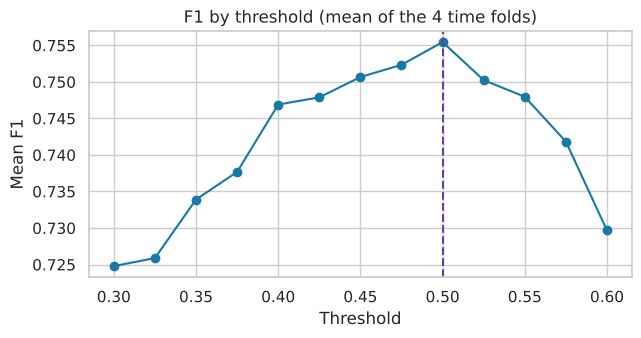

Mean F1 by threshold: {0.3: 0.725, 0.325: 0.726, 0.35: 0.734, 0.375: 0.738, 0.4: 0.747, 0.425: 0.748, 0.45: 0.751, 0.475: 0.752, 0.5: 0.755, 0.525: 0.75, 0.55: 0.748, 0.575: 0.742, 0.6: 0.73}
Best threshold: 0.5, compared with 0.5: tie, threshold used: 0.5


In [30]:
FINAL_MODEL_NAME = "Logistic regression"
final_search = searches[FINAL_MODEL_NAME]
final_pipeline = clone(final_search.best_estimator_)


# probabilities of the validation rows of every inner fold, refitted per fold
def out_of_fold_probabilities(pipeline):
    probabilities = []
    for fit_idx, val_idx in inner_folds:
        fitted = clone(pipeline).fit(X_dev.iloc[fit_idx], y_dev.iloc[fit_idx])
        probabilities.append(fitted.predict_proba(X_dev.iloc[val_idx])[:, 1])
    return probabilities


fold_probabilities = out_of_fold_probabilities(final_pipeline)
thresholds = np.round(np.arange(0.30, 0.61, 0.025), 3)
threshold_curve = pd.DataFrame({
    threshold: [f1_score(y_dev.iloc[val_idx], probability >= threshold)
                for (_, val_idx), probability in zip(inner_folds, fold_probabilities)]
    for threshold in thresholds}).T

best_threshold = float(threshold_curve.mean(axis=1).idxmax())
threshold_check = compare_folds(threshold_curve.loc[best_threshold], threshold_curve.loc[0.5])
THRESHOLD = best_threshold if threshold_check["Verdict"] == "better" else 0.5

ax = threshold_curve.mean(axis=1).plot(marker="o", color=PLOT_BLUE, figsize=(7, 3.2))
ax.axvline(THRESHOLD, color=PLOT_PURPLE, linestyle="--")
ax.set(title="F1 by threshold (mean of the 4 time folds)", xlabel="Threshold", ylabel="Mean F1")
plt.show()
print("Mean F1 by threshold:", threshold_curve.mean(axis=1).round(3).to_dict())
print(f"Best threshold: {best_threshold}, compared with 0.5: {threshold_check['Verdict']}, "
      f"threshold used: {THRESHOLD}")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision</b></p>
<ul>
  <li>13 thresholds from 0.30 to 0.60 are tested. The F1 is highest <b>at 0.5</b> (0.755), nearly flat from 0.45 to 0.50 (0.751 to 0.755) and falls on both sides (0.725 at 0.30, 0.730 at 0.60) --> <b>threshold 0.5</b> stays</li>
</ul>

</div>

<h3>Final check on the holdout</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>Features, model, hyperparameters and threshold are fixed. Now the holdout is used for the first and only time.</p>

</div>

In [31]:
# first use of the holdout: fit on the development part, predict the holdout
final_pipeline.fit(X_dev, y_dev)
holdout_probability = final_pipeline.predict_proba(X_holdout)[:, 1]
holdout_prediction = (holdout_probability >= THRESHOLD).astype(int)
holdout_f1 = f1_score(y_holdout, holdout_prediction)
holdout_auc = roc_auc_score(y_holdout, holdout_probability)
no_repeat_right, false_repeat, missed_repeat, repeat_right = confusion_matrix(
    y_holdout, holdout_prediction).ravel()

print(f"Final model on the holdout: F1 {holdout_f1:.4f}, AUC {holdout_auc:.4f}, "
      f"share of predicted repeats {holdout_prediction.mean():.3f}")
print(f"Always predicting a repeat: F1 {baseline_holdout:.4f}")
print(f"Right: {repeat_right} repeats and {no_repeat_right} non-repeats. "
      f"Wrong: {false_repeat} predicted repeats that did not happen, {missed_repeat} missed repeats\n")
print(classification_report(y_holdout, holdout_prediction, target_names=["no repeat", "repeat"],
                            digits=3))

Final model on the holdout: F1 0.7836, AUC 0.8150, share of predicted repeats 0.592
Always predicting a repeat: F1 0.7530
Right: 505 repeats and 294 non-repeats. Wrong: 133 predicted repeats that did not happen, 146 missed repeats

              precision    recall  f1-score   support

   no repeat      0.668     0.689     0.678       427
      repeat      0.792     0.776     0.784       651

    accuracy                          0.741      1078
   macro avg      0.730     0.732     0.731      1078
weighted avg      0.743     0.741     0.742      1078



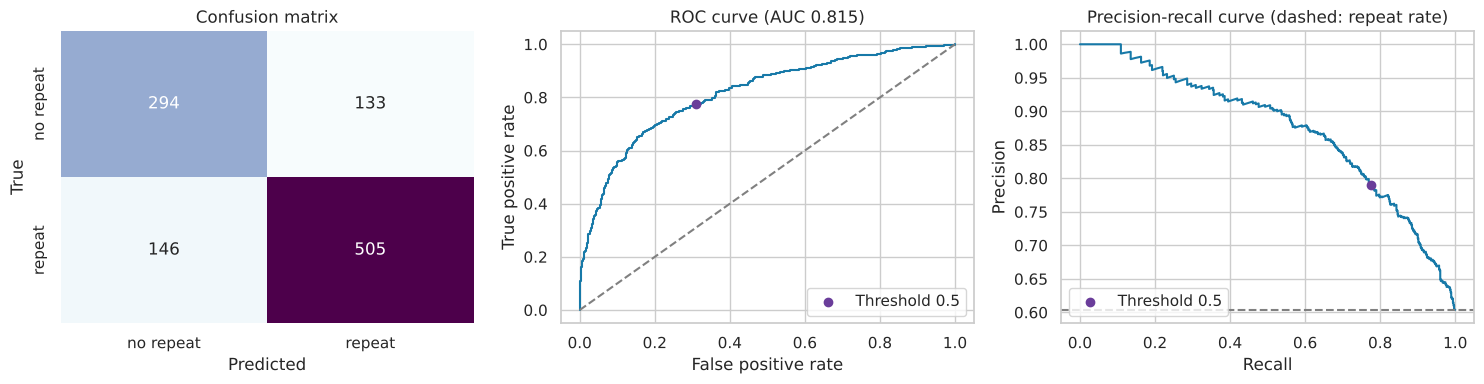

In [32]:
# confusion matrix, ROC curve and precision-recall curve of the holdout
false_positive_rate, true_positive_rate, roc_thresholds = roc_curve(y_holdout, holdout_probability)
precision, recall, pr_thresholds = precision_recall_curve(y_holdout, holdout_probability)
roc_point = np.argmin(np.abs(roc_thresholds - THRESHOLD))
pr_point = np.argmin(np.abs(pr_thresholds - THRESHOLD))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.heatmap(confusion_matrix(y_holdout, holdout_prediction), annot=True, fmt="d", cmap="BuPu",
            cbar=False, xticklabels=["no repeat", "repeat"], yticklabels=["no repeat", "repeat"],
            ax=axes[0])
axes[0].set(title="Confusion matrix", xlabel="Predicted", ylabel="True")
axes[1].plot(false_positive_rate, true_positive_rate, color=PLOT_BLUE)
axes[1].plot([0, 1], [0, 1], color="grey", linestyle="--")
axes[1].scatter(false_positive_rate[roc_point], true_positive_rate[roc_point], color=PLOT_PURPLE,
                zorder=3, label=f"Threshold {THRESHOLD}")
axes[1].set(title=f"ROC curve (AUC {holdout_auc:.3f})", xlabel="False positive rate",
            ylabel="True positive rate")
axes[1].legend(loc="lower right")
axes[2].plot(recall, precision, color=PLOT_BLUE)
axes[2].axhline(y_holdout.mean(), color="grey", linestyle="--")
axes[2].scatter(recall[pr_point], precision[pr_point], color=PLOT_PURPLE, zorder=3,
                label=f"Threshold {THRESHOLD}")
axes[2].set(title="Precision-recall curve (dashed: repeat rate)", xlabel="Recall", ylabel="Precision")
axes[2].legend(loc="lower left")
plt.tight_layout()
plt.show()

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>The final model reaches an <b>F1 of 0.784</b> (precision 0.792, recall 0.776) and an <b>AUC of 0.815</b> on the holdout, against an F1 of 0.753 for always predicting a repeat</li>
  <li>The F1 is higher than on the time folds (0.755) because this period has more repeats (0.604), which also lifts the baseline. The AUC is higher too (0.815 against 0.801) --> <b>no sign of overfitting</b> to the development part</li>
  <li>The two error types are balanced: 133 predicted repeats that did not happen, 146 missed repeats</li>
  <li>--> our estimate for Kaggle is an F1 of about <b>0.78</b>, if test.csv has a similar repeat rate</li>
</ul>

</div>

<h3>Final model</h3>

In [33]:
# refit on all training purchases and save the final model for notebook 3
final_pipeline.fit(train.drop(columns=TARGET), train[TARGET])
final_parameters = {name.replace("model__", ""): value
                    for name, value in final_search.best_params_.items()}
final_summary = search_summary(final_search)
final_model = {
    "model": FINAL_MODEL_NAME, "parameters": final_parameters, "threshold": THRESHOLD,
    "numeric": FINAL_NUMERIC, "flags": FINAL_FLAGS, "categorical": FINAL_CATEGORICAL,
    "cv_f1": round(float(final_summary["CV F1"]), 4), "cv_auc": round(float(final_summary["CV AUC"]), 4),
    "holdout_f1": round(float(holdout_f1), 4), "holdout_auc": round(float(holdout_auc), 4),
}
Path("../logs").mkdir(exist_ok=True)
Path("../logs/final_model.json").write_text(json.dumps(final_model, indent=2) + "\n",
                                            encoding="utf-8")
print(f"Saved logs/final_model.json: {FINAL_MODEL_NAME}, {final_parameters}, threshold {THRESHOLD}, "
      f"{len(final_variables)} variables")

Saved logs/final_model.json: Logistic regression, {'C': 0.003}, threshold 0.5, 21 variables


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>The final pipeline is refitted on all 6,469 training rows, and its settings are saved in <b>logs/final_model.json</b> for Notebook 3.</p>

</div>

<h3>Limitations</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  With 4 folds the standard error of a difference is itself uncertain, so a tie is a careful verdict and not a proof
  
</ul>

</div>